# Notebook 3 — Modeling and Evaluation

**Previous:** [Notebook 1 — Data cleaning and EDA](1_data_cleaning_and_eda.ipynb) ·
[Notebook 2 — PCA and regimes](2_yield_curve_pca_and_regimes.ipynb)

**Task:** supervised **binary classification**. For each trading day, predict whether the 10-year Treasury yield will be
**higher (1) or not (0) in 21 trading days**, using the 15 features built in Notebook 1.

**Plan**

1. Split the data **chronologically** — train on the past, test on the most recent 20%.
2. Set honest **baselines** a model must beat.
3. Choose and justify the **evaluation metric**.
4. Train **five classifiers**, each tuned with **grid search** and **time-series cross-validation**.
5. Compare them, interpret the best one, and stress-test the result.

In [1]:
from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, KFold, GridSearchCV, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

PROCESSED_DIR = Path("../data/processed")
IMG_DIR = Path("../images")
RANDOM_STATE = 42
HORIZON = 21          # forecast horizon in trading days; also the gap between train and test
TEST_SHARE = 0.20

df = pd.read_csv(PROCESSED_DIR / "model_dataset.csv", index_col=0, parse_dates=True)
FEATURES = [c for c in df.columns if c not in ("fwd_chg_10y_bp", "target_up")]

# Plain-English names for charts
FEATURE_LABELS = {
    "level_10y_vs_1y": "10Y yield vs its 1-year average", "slope_10y_2y": "Curve slope: 10Y minus 2Y",
    "slope_10y_3m": "Curve slope: 10Y minus 3M", "butterfly_2s5s10s": "Curve curvature (2s5s10s)",
    "mom_10y_21d": "10Y change over last month", "mom_10y_63d": "10Y change over last 3 months",
    "vol_10y_21d": "10Y volatility (last month)", "spread_10y_fedfunds": "10Y minus fed funds rate",
    "fedfunds_chg_63d": "Fed funds change (3 months)", "real_yield_vs_1y": "Real yield vs its 1-year average",
    "cpi_yoy_chg_3m": "Change in inflation (3 months)", "vix": "VIX level", "vix_chg_21d": "VIX change (last month)",
    "oil_ret_21d": "Oil price change (last month)", "dollar_ret_21d": "Dollar change (last month)"}
print(f"{len(df):,} rows, {len(FEATURES)} features, {df.index.min():%Y-%m-%d} to {df.index.max():%Y-%m-%d}")

5,115 rows, 15 features, 2006-02-02 to 2026-09-09


## 1. Train / test split — strictly in time order

Shuffling rows randomly (the usual approach) is **wrong for financial time series**: the model would be trained on
days *after* the days it is tested on, and would effectively see the future. We therefore:

- keep the **last 20% of days as the test set**, untouched until the final evaluation;
- leave a **21-day gap** between the end of training and the start of testing. Each target looks 21 days ahead, so
  without the gap the last training targets would overlap the first test days.

In [3]:
split_idx = int(len(df) * (1 - TEST_SHARE))
train = df.iloc[: split_idx - HORIZON]   # drop the last HORIZON rows: their outcomes fall inside the test window
test = df.iloc[split_idx:]

X_train, y_train = train[FEATURES], train["target_up"]
X_test, y_test = test[FEATURES], test["target_up"]

pd.DataFrame({
    "rows": [len(train), len(test)],
    "from": [train.index.min().date(), test.index.min().date()],
    "to": [train.index.max().date(), test.index.max().date()],
    "share of rises": [y_train.mean(), y_test.mean()],
}, index=["train", "test"]).round(3)

,rows,from,to,share of rises
train,4071,2006-02-02,2022-05-10,0.478
test,1023,2022-06-10,2026-09-09,0.539


## 2. Baselines a model must beat

| Baseline | Rule | Why it matters |
|---|---|---|
| **Majority class** | Always predict the outcome most common in the training data | Any model must beat "always guess the same" |
| **Persistence** | Predict that the 10-year keeps moving the way it moved over the past month | The traders' rule of thumb ("the trend is your friend") — a tougher bar |

In [4]:
majority_class = int(y_train.mean() >= 0.5)
majority_pred = np.full(len(y_test), majority_class)
persistence_pred = (X_test["mom_10y_21d"] > 0).astype(int)

baselines = pd.DataFrame([
    {"model": "Baseline: majority class", "test accuracy": accuracy_score(y_test, majority_pred), "test ROC-AUC": 0.5},
    {"model": "Baseline: persistence", "test accuracy": accuracy_score(y_test, persistence_pred),
     "test ROC-AUC": roc_auc_score(y_test, X_test["mom_10y_21d"])},
]).set_index("model")
baselines.round(3)

,test accuracy,test ROC-AUC
model,,
Baseline: majority class,0.461,0.500
Baseline: persistence,0.515,0.486


## 3. Choice of evaluation metric

**Primary metric: ROC-AUC (area under the ROC curve).**

- *What it measures:* the probability that the model gives a higher "rise" score to a randomly chosen day that
  was followed by a rise than to one that was followed by a fall. **0.5 = coin flip, 1.0 = perfect.**
- *Why it suits this problem:* (1) it judges the model's **ranking of days by confidence**, which is what a portfolio
  manager uses to size a position, not just a yes/no call; (2) it does not depend on picking a 0.5 cut-off, and the
  right cut-off depends on each user's cost of being wrong; (3) it is not fooled by class imbalance, which varies a lot
  from year to year (Notebook 1, section 6.6).

**Secondary metric: accuracy (hit rate)** — the share of correct up/down calls. Easy to explain and directly comparable
with the baselines. We also report precision, recall and F1.

**What a realistic result looks like.** The Treasury market is extremely efficient. An honest model should land
around **ROC-AUC 0.55–0.65**. Anything above ~0.70 must be treated very cautiously.

## 4. Model training: five classifiers, grid search, time-series cross-validation

- Every model is a **pipeline** of `StandardScaler` + classifier, so scaling is learned only from each training fold.
- **Cross-validation:** `TimeSeriesSplit` with 5 folds — each fold trains on the past and validates on the following
  period, with a 21-day gap. This mirrors how the model would be used in real life.
- **Hyperparameters:** chosen by `GridSearchCV`, optimising ROC-AUC.
- **Model selection rule:** the winner is the model with the best **cross-validated** AUC. The test set is used
  only once, at the end, to report performance — never to choose.

In [5]:
cv = TimeSeriesSplit(n_splits=5, gap=HORIZON)

models = {
    "Logistic Regression": (
        LogisticRegression(solver="liblinear", max_iter=2000),
        {"clf__C": [0.001, 0.01, 0.1, 1, 10], "clf__penalty": ["l1", "l2"]}),
    "K-Nearest Neighbors": (
        KNeighborsClassifier(),
        {"clf__n_neighbors": [25, 51, 101, 201], "clf__weights": ["uniform", "distance"]}),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"clf__max_depth": [2, 3, 4, 6], "clf__min_samples_leaf": [50, 100, 200]}),
    "Support Vector Machine": (
        SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
        {"clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.01]}),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
        {"clf__max_depth": [3, 5, 8], "clf__min_samples_leaf": [50, 100], "clf__max_features": ["sqrt", 0.5]}),
}

searches, rows = {}, []
for name, (estimator, grid) in models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("clf", estimator)])
    search = GridSearchCV(pipe, grid, cv=cv, scoring="roc_auc", n_jobs=-1)
    start = time.time()
    search.fit(X_train, y_train)
    fit_seconds = time.time() - start
    searches[name] = search

    best = search.best_estimator_
    proba = best.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    rows.append({"model": name,
                 "CV ROC-AUC": search.best_score_,
                 "CV std": search.cv_results_["std_test_score"][search.best_index_],
                 "test ROC-AUC": roc_auc_score(y_test, proba),
                 "test accuracy": accuracy_score(y_test, pred),
                 "precision": precision_score(y_test, pred, zero_division=0),
                 "recall": recall_score(y_test, pred, zero_division=0),
                 "F1": f1_score(y_test, pred, zero_division=0),
                 "tuning time (s)": fit_seconds,
                 "best parameters": {k.replace("clf__", ""): v for k, v in search.best_params_.items()}})
    print(f"{name:<24} CV AUC {search.best_score_:.3f} | test AUC {rows[-1]['test ROC-AUC']:.3f} | "
          f"{fit_seconds:5.1f}s")

results = pd.DataFrame(rows).set_index("model").sort_values("CV ROC-AUC", ascending=False)

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarnin

Logistic Regression      CV AUC 0.572 | test AUC 0.520 |   1.5s
K-Nearest Neighbors      CV AUC 0.557 | test AUC 0.551 |   0.2s
Decision Tree            CV AUC 0.480 | test AUC 0.551 |   0.1s
Support Vector Machine   CV AUC 0.559 | test AUC 0.521 |   2.0s


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warn

Random Forest            CV AUC 0.522 | test AUC 0.565 |   2.9s


In [6]:
# Full comparison table, with the baselines underneath for reference
comparison = pd.concat([results.drop(columns="best parameters"), baselines])
comparison.round(3)

,CV ROC-AUC,CV std,test ROC-AUC,test accuracy,precision,recall,F1,tuning time (s)
model,,,,,,,,
Logistic Regression,0.572,0.054,0.520,0.512,0.686,0.174,0.278,1.488
Support Vector Machine,0.559,0.062,0.521,0.529,0.601,0.374,0.461,2.036
K-Nearest Neighbors,0.557,0.040,0.551,0.494,0.551,0.323,0.407,0.169
Random Forest,0.522,0.044,0.565,0.492,0.599,0.171,0.266,2.946
Decision Tree,0.480,0.065,0.551,0.575,0.594,0.666,0.628,0.121
Baseline: majority class,NaN,NaN,0.500,0.461,NaN,NaN,NaN,NaN
Baseline: persistence,NaN,NaN,0.486,0.515,NaN,NaN,NaN,NaN


In [7]:
results[["best parameters"]]

,best parameters
model,
Logistic Regression,"{'C': 10, 'penalty': 'l2'}"
Support Vector Machine,"{'C': 0.1, 'gamma': 0.01}"
K-Nearest Neighbors,"{'n_neighbors': 25, 'weights': 'uniform'}"
Random Forest,"{'max_depth': 3, 'max_features': 0.5, 'min_sam..."
Decision Tree,"{'max_depth': 6, 'min_samples_leaf': 200}"


## 5. Model comparison

Selected model (highest cross-validated ROC-AUC): Logistic Regression


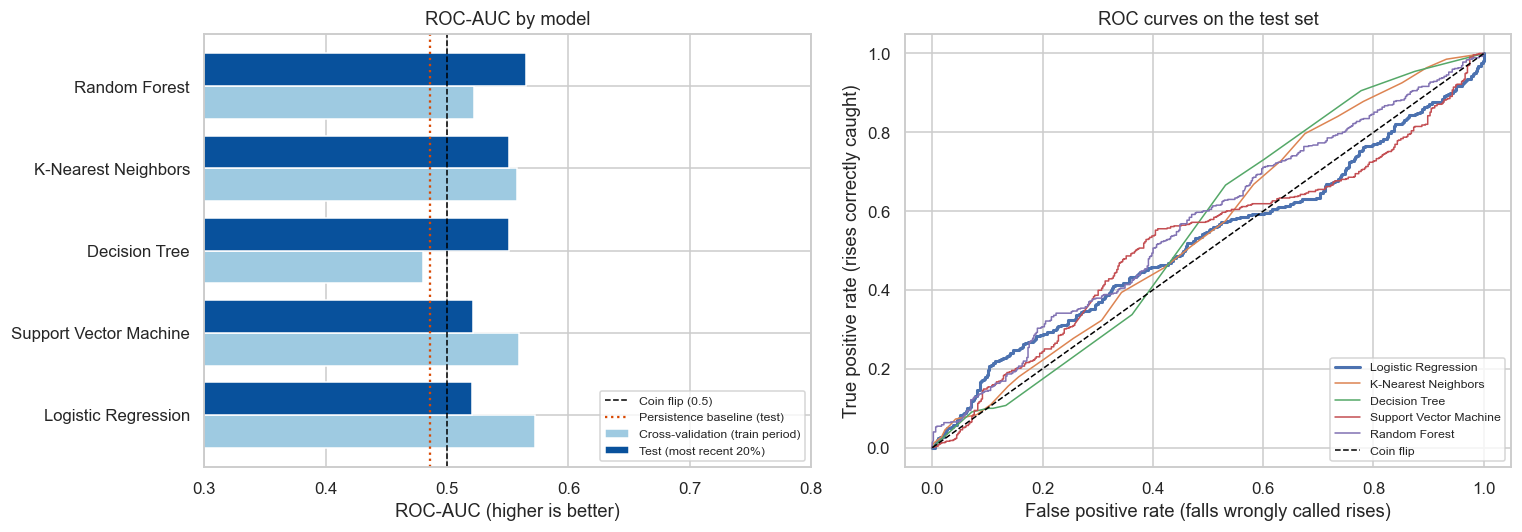

In [8]:
BEST_MODEL = results.index[0]          # chosen on cross-validation score, not on the test set
best_search = searches[BEST_MODEL]
print(f"Selected model (highest cross-validated ROC-AUC): {BEST_MODEL}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: CV vs test AUC for each model
plot_df = results[["CV ROC-AUC", "test ROC-AUC"]].sort_values("test ROC-AUC")
y_pos = np.arange(len(plot_df))
axes[0].barh(y_pos - 0.2, plot_df["CV ROC-AUC"], height=0.4, color="#9ecae1", label="Cross-validation (train period)")
axes[0].barh(y_pos + 0.2, plot_df["test ROC-AUC"], height=0.4, color="#08519c", label="Test (most recent 20%)")
axes[0].axvline(0.5, color="black", ls="--", lw=1, label="Coin flip (0.5)")
axes[0].axvline(baselines.loc["Baseline: persistence", "test ROC-AUC"], color="#d94801", ls=":", lw=1.5,
                label="Persistence baseline (test)")
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(plot_df.index)
axes[0].set_xlim(0.3, 0.8)
axes[0].set_title("ROC-AUC by model")
axes[0].set_xlabel("ROC-AUC (higher is better)")
axes[0].legend(loc="lower right", fontsize=8)

# Right: ROC curves on the test set
for name, search in searches.items():
    fpr, tpr, _ = roc_curve(y_test, search.best_estimator_.predict_proba(X_test)[:, 1])
    axes[1].plot(fpr, tpr, lw=2 if name == BEST_MODEL else 1, label=name)
axes[1].plot([0, 1], [0, 1], color="black", ls="--", lw=1, label="Coin flip")
axes[1].set_title("ROC curves on the test set")
axes[1].set_xlabel("False positive rate (falls wrongly called rises)")
axes[1].set_ylabel("True positive rate (rises correctly caught)")
axes[1].legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(IMG_DIR / "08_model_comparison.png", bbox_inches="tight")
plt.show()

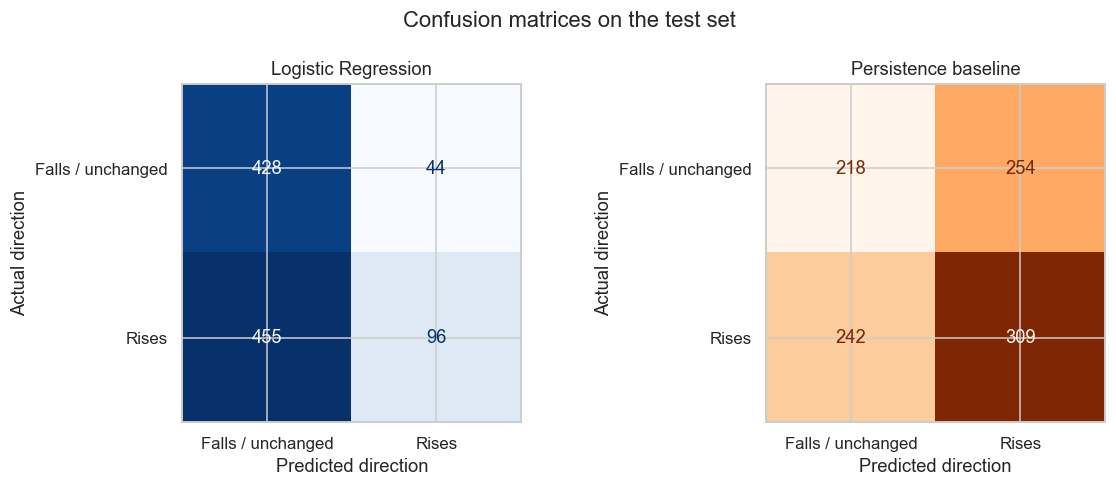

In [9]:
best_model = best_search.best_estimator_
best_proba = best_model.predict_proba(X_test)[:, 1]
best_pred = (best_proba >= 0.5).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
labels = ["Falls / unchanged", "Rises"]
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, display_labels=labels, cmap="Blues", ax=axes[0],
                                        colorbar=False)
axes[0].set_title(f"{BEST_MODEL}")
ConfusionMatrixDisplay.from_predictions(y_test, persistence_pred, display_labels=labels, cmap="Oranges", ax=axes[1],
                                        colorbar=False)
axes[1].set_title("Persistence baseline")
for ax in axes:
    ax.set_xlabel("Predicted direction")
    ax.set_ylabel("Actual direction")
fig.suptitle("Confusion matrices on the test set")
fig.tight_layout()
plt.show()

**Interpretation.**

- All five models beat a coin flip in cross-validation, but only modestly (ROC-AUC 0.48–0.57), and **every model scores
  lower on the test period than in cross-validation** except the two weakest — a sign that the 2022–26 rate cycle
  behaves differently from 2006–22.
- **Logistic regression is selected** because it has the best cross-validated AUC. It is also the simplest and most
  interpretable model.
- The decision tree has the *worst* cross-validated score yet the best test accuracy. Picking it *because* of the test
  result would be cheating (choosing on the answer sheet) — and its poor cross-validation suggests the good test result
  is luck.
- The selected model is **cautious about calling rises** (low recall at the 0.5 threshold): its training period
  (2006–22) had more falls than rises, while the test period had more rises.

### Choosing the decision threshold

A 0.5 cut-off is a convention, not a law. A pension fund that loses more when yields rise unexpectedly may want to act
on lower "rise" probabilities. The table shows the trade-off: a lower threshold catches more rises (higher recall) at
the cost of more false alarms (lower precision).

In [11]:
threshold_rows = []
for threshold in [0.40, 0.45, 0.50, 0.55, 0.60]:
    pred_t = (best_proba >= threshold).astype(int)
    threshold_rows.append({"threshold": threshold, "share of days called 'rise'": pred_t.mean(),
                           "accuracy": accuracy_score(y_test, pred_t),
                           "precision": precision_score(y_test, pred_t, zero_division=0),
                           "recall": recall_score(y_test, pred_t, zero_division=0)})
pd.DataFrame(threshold_rows).set_index("threshold").round(3)

,share of days called 'rise',accuracy,precision,recall
threshold,,,,
0.40,0.357,0.523,0.586,0.388
0.45,0.200,0.527,0.663,0.247
0.50,0.137,0.512,0.686,0.174
0.55,0.068,0.481,0.643,0.082
0.60,0.005,0.462,0.600,0.005


## 6. Interpreting the models

**(a) Logistic regression coefficients.** Because features are standardised, each coefficient shows how much one
standard deviation of that feature moves the odds of a rise. Positive = pushes towards "rise".

**(b) Permutation importance for the selected model.** We shuffle one feature at a time on the test set and measure
how much ROC-AUC drops. A big drop means the model relies on that feature.

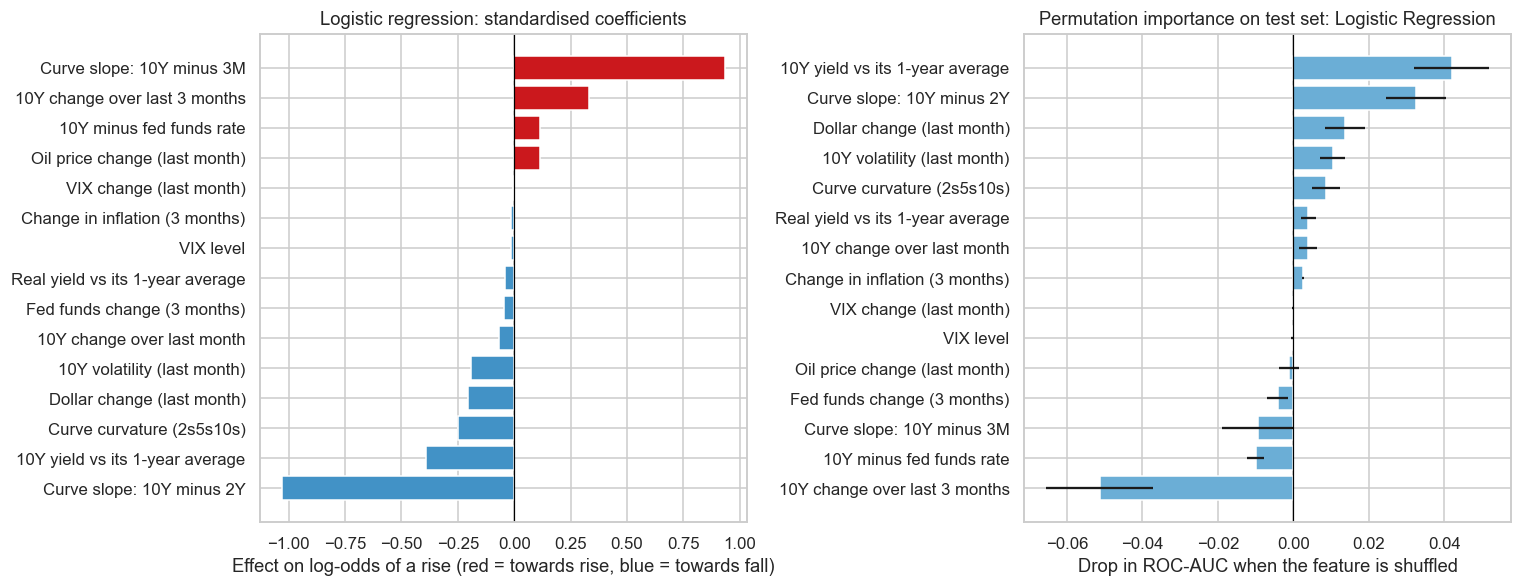

Top 5 features for the selected model: 10Y yield vs its 1-year average, Curve slope: 10Y minus 2Y, Dollar change (last month), 10Y volatility (last month), Curve curvature (2s5s10s)


In [13]:
logit = searches["Logistic Regression"].best_estimator_.named_steps["clf"]
coefs = pd.Series(logit.coef_[0], index=FEATURES).sort_values()

perm = permutation_importance(best_model, X_test, y_test, scoring="roc_auc", n_repeats=10,
                              random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=FEATURES).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].barh(coefs.index.map(FEATURE_LABELS), coefs.values, color=np.where(coefs.values > 0, "#cb181d", "#4292c6"))
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_title("Logistic regression: standardised coefficients")
axes[0].set_xlabel("Effect on log-odds of a rise (red = towards rise, blue = towards fall)")

axes[1].barh(importance.index.map(FEATURE_LABELS), importance.values, color="#6baed6",
             xerr=pd.Series(perm.importances_std, index=FEATURES)[importance.index])
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_title(f"Permutation importance on test set: {BEST_MODEL}")
axes[1].set_xlabel("Drop in ROC-AUC when the feature is shuffled")
fig.tight_layout()
fig.savefig(IMG_DIR / "09_feature_importance.png", bbox_inches="tight")
plt.show()

print("Top 5 features for the selected model:",
      ", ".join(importance.sort_values(ascending=False).index[:5].map(FEATURE_LABELS)))

**Interpretation.**

- **Where the 10-year sits relative to its recent past matters most.** When the yield is above its 1-year average, the
  model leans towards a fall next month (mean reversion). Shuffling this feature costs the most AUC on the test set.
- **The two curve slopes must be read together.** 10Y–2Y and 10Y–3M are highly correlated, so their large coefficients
  of opposite sign largely offset; what the model is picking up is the *difference* between them — whether the very front
  of the curve (bills, tied to the Fed) is moving away from the 2-year (which anticipates future Fed moves).
- **Recent volatility and a rising dollar** tilt the model towards falls, consistent with flight-to-safety buying of
  Treasuries in stressed markets.
- **Some features hurt on the test set** (negative permutation importance, e.g. 3-month momentum): relationships that
  held from 2006 to 2022 did not hold after 2022. This is the regime instability seen in Notebook 2.

## 7. Stress tests: is the result real?

### 7.1 What happens if we validate the wrong way?

Here we re-run cross-validation for the selected model with ordinary **shuffled k-fold**, which mixes future and past
days. Because neighbouring days share almost the same 21-day outcome, the model can "recognise" test days from
their neighbours in training.

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarnin

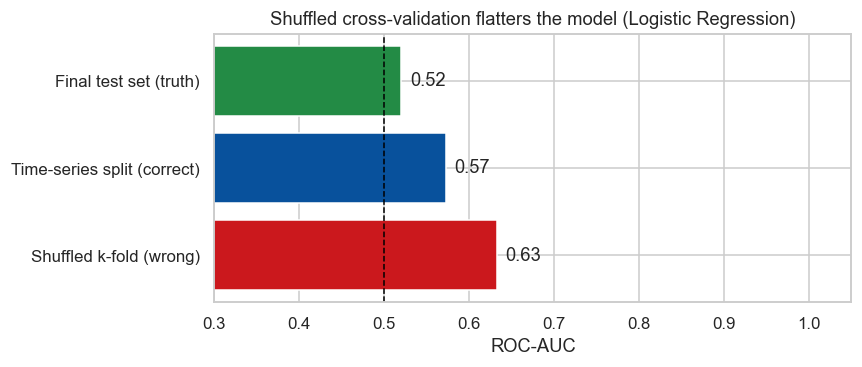

,validation method,ROC-AUC
0,Shuffled k-fold (wrong),0.632
1,Time-series split (correct),0.572
2,Final test set (truth),0.520


In [14]:
shuffled_cv = cross_val_score(best_model, X_train, y_train, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
                              scoring="roc_auc", n_jobs=-1)
time_cv = cross_val_score(best_model, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)

leak = pd.DataFrame({"validation method": ["Shuffled k-fold (wrong)", "Time-series split (correct)",
                                           "Final test set (truth)"],
                     "ROC-AUC": [shuffled_cv.mean(), time_cv.mean(), roc_auc_score(y_test, best_proba)]})

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(leak["validation method"], leak["ROC-AUC"], color=["#cb181d", "#08519c", "#238b45"])
ax.axvline(0.5, color="black", ls="--", lw=1)
for i, v in enumerate(leak["ROC-AUC"]):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center")
ax.set_xlim(0.3, 1.05)
ax.set_title(f"Shuffled cross-validation flatters the model ({BEST_MODEL})")
ax.set_xlabel("ROC-AUC")
fig.tight_layout()
fig.savefig(IMG_DIR / "10_validation_leakage.png", bbox_inches="tight")
plt.show()
leak.round(3)

Shuffled k-fold reports a much better score than the model can actually deliver on unseen future data. 

### 7.2 A second trap: features that carry a long-term trend

The first version of this project fed the models the **raw** 10-year yield, real yield and inflation rate. Those
models scored well in cross-validation (ROC-AUC about 0.60) but collapsed on the 2022–26 test period (test ROC-AUC
0.48–0.56, with accuracy *below* the persistence baseline): they had learned "high yields are followed by falls" from the
2006–2021 decline in rates, and almost never predicted a rise once rates started climbing. Because Notebook 1 shows the
yield level is non-stationary, those inputs were replaced with **deviations from their own 1-year average** (and the
*change* in inflation). The results in this notebook use the corrected features. The lesson is the same as in 7.1:
a model can look good in validation for reasons that will not hold in the future.

### 7.3 Non-overlapping months

Consecutive test days share most of their 21-day outcome window, so the ~1,000 test days contain far fewer truly
independent observations. Here we keep one day every 21 trading days and recompute.

In [15]:
step = slice(None, None, HORIZON)
y_monthly = y_test.iloc[step]
monthly = pd.DataFrame({
    "model": [BEST_MODEL, "Baseline: persistence"],
    "accuracy": [accuracy_score(y_monthly, best_pred[step]), accuracy_score(y_monthly, persistence_pred.iloc[step])],
    "ROC-AUC": [roc_auc_score(y_monthly, best_proba[step]), roc_auc_score(y_monthly, X_test["mom_10y_21d"].iloc[step])],
})
print(f"Independent monthly observations in the test set: {len(y_monthly)}")
monthly.round(3)

Independent monthly observations in the test set: 49


,model,accuracy,ROC-AUC
0,Logistic Regression,0.531,0.497
1,Baseline: persistence,0.531,0.512


With only about 50 independent months, the model and persistence are indistinguishable. Any difference of a few
percentage points on a sample this size is well within the range of luck (one extra correct call is two points).

### 7.4 Is the edge stable over time?

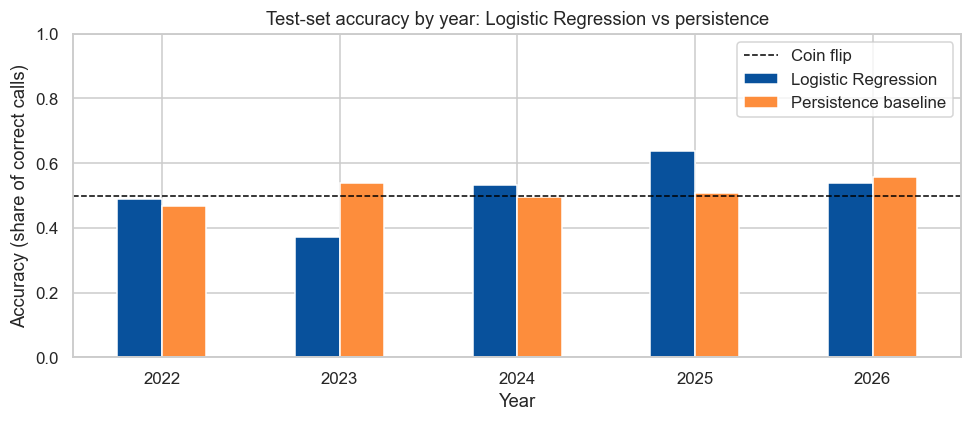

,days,share of rises,model accuracy,persistence accuracy
year,,,,
2022,139.0,0.489,0.489,0.468
2023,250.0,0.628,0.372,0.540
2024,250.0,0.488,0.532,0.496
2025,230.0,0.404,0.639,0.509
2026,154.0,0.721,0.539,0.558


In [16]:
yearly = (pd.DataFrame({"year": y_test.index.year, "y": y_test.values, "proba": best_proba, "pred": best_pred,
                        "persist": persistence_pred.values})
          .groupby("year")
          .apply(lambda g: pd.Series({"days": len(g), "share of rises": g["y"].mean(),
                                      "model accuracy": accuracy_score(g["y"], g["pred"]),
                                      "persistence accuracy": accuracy_score(g["y"], g["persist"])}),
                 include_groups=False))

fig, ax = plt.subplots(figsize=(9, 4))
yearly[["model accuracy", "persistence accuracy"]].plot(kind="bar", ax=ax, color=["#08519c", "#fd8d3c"], rot=0)
ax.axhline(0.5, color="black", ls="--", lw=1)
ax.set_title(f"Test-set accuracy by year: {BEST_MODEL} vs persistence")
ax.set_xlabel("Year")
ax.set_ylabel("Accuracy (share of correct calls)")
ax.set_ylim(0, 1)
ax.legend(["Coin flip", BEST_MODEL, "Persistence baseline"], loc="upper right")
fig.tight_layout()
plt.show()
yearly.round(3)

The model's hit rate swings from well below a coin flip (2023, a year of mostly rising yields that the model kept
calling as falls) to clearly above it (2025). **The edge, where it exists, is regime-dependent and not reliable year to
year.**

## 8. Results summary

In [17]:
best_row = results.loc[BEST_MODEL]
persist_acc = baselines.loc["Baseline: persistence", "test accuracy"]
persist_auc = baselines.loc["Baseline: persistence", "test ROC-AUC"]
majority_acc = baselines.loc["Baseline: majority class", "test accuracy"]

summary = pd.DataFrame({
    "metric": ["Selected model", "Cross-validated ROC-AUC", "Test ROC-AUC", "Test accuracy",
               "Persistence accuracy", "Persistence ROC-AUC", "Majority-class accuracy",
               "Accuracy gain vs persistence (pp)", "Accuracy gain vs majority (pp)"],
    "value": [BEST_MODEL, f"{best_row['CV ROC-AUC']:.3f}", f"{best_row['test ROC-AUC']:.3f}",
              f"{best_row['test accuracy']:.1%}", f"{persist_acc:.1%}", f"{persist_auc:.3f}", f"{majority_acc:.1%}",
              f"{(best_row['test accuracy'] - persist_acc) * 100:+.1f}",
              f"{(best_row['test accuracy'] - majority_acc) * 100:+.1f}"],
}).set_index("metric")

# Sanity check from the project's own data-quality incident: a near-perfect score means a bug, not a breakthrough
assert best_row["test ROC-AUC"] < 0.80, "Suspiciously high AUC - check for leakage or a truncated input."
assert len(X_test) > 500, "Test set unexpectedly small - check for a truncated input series."

comparison.round(3).to_csv(PROCESSED_DIR / "model_comparison.csv")
summary

,value
metric,
Selected model,Logistic Regression
Cross-validated ROC-AUC,0.572
Test ROC-AUC,0.520
Test accuracy,51.2%
Persistence accuracy,51.5%
Persistence ROC-AUC,0.486
Majority-class accuracy,46.1%
Accuracy gain vs persistence (pp),-0.3
Accuracy gain vs majority (pp),+5.1


## 9. Conclusions

1. **The Treasury market is close to efficient at a one-month horizon.** With 15 carefully built features, the best
   model (logistic regression) reaches a cross-validated ROC-AUC of about 0.57 and a test ROC-AUC of about 0.52, with
   accuracy roughly equal to the simple persistence rule. This is a **negative result**, and it is consistent with
   decades of academic research on bond-market predictability.
2. **Simple models are as good as complex ones.** No model was reliably better than logistic regression; extra
   flexibility (trees, kernels, forests) mostly fitted noise from the training period.
3. **What little signal exists is economically sensible** — mean reversion of the 10-year towards its recent average,
   the shape of the front end of the curve, volatility and the dollar — but it **depends on the regime** and did not carry
   over cleanly into the 2022–26 tightening cycle.
4. **Validation design matters more than model choice.** Shuffled cross-validation flattered the model (AUC about 0.63
   vs 0.52 on truly unseen data), and features carrying a long-term trend produced a model that looked good and then
   failed. Both traps are documented here so they are not repeated.
5. **The descriptive results are robust and useful on their own**: three factors explain about 92% of curve movements,
   and the curve falls into a handful of recognisable rate regimes (Notebook 2).

**Next steps** are set out in the [README](../README.md): add forward-looking information (Fed funds futures, economic
data surprises, Treasury supply), re-fit models walk-forward within regimes, and judge any signal by its value in a
hedging decision after transaction costs rather than by accuracy alone.

**Next:** [Notebook 4 — Improvement experiments](4_improvement_experiments.ipynb) tests these ideas.